## Deep Learning Project: Wine Classification Using Encoder–Decoder

### Dataset

* **Dataset:** Wine Dataset from Scikit-learn
* **Number of samples:** 178
* **Number of features:** 13
* **Number of classes:** 3
* **Task:** Multiclass Classification
  

### Project Tasks

1. **Load Dataset**

   * Load the Wine dataset.
   * Convert it into a DataFrame.
   * Display the features, target, and class distribution.

2. **EDA**

   * Statistical analysis.
   * Distribution plots.
   * Box plots.
   * Correlation heatmap.
   * Class distribution visualization.

3. **Preprocessing**

   * Split features and target.
   * Train-test split (80/20).
   * Apply StandardScaler.

4. **Implement Encoder**

   * Input: 13 features.
   * Dense layers: 64 → 32.
   * Latent representation: 5 features.
   * Activation: ReLU.

5. **Implement Decoder**

   * Input: 5 encoded features.
   * Dense layers: 32 → 64.
   * Output: 13 reconstructed features.

6. **Train Encoder–Decoder**

   * Optimizer: Adam.
   * Loss: MSE.
   * Epochs: 100.
   * Plot training and validation loss.

7. **Extract Encoded Features**

   * Transform original 13 features into 5 encoded features.

8. **Deep Learning Classification**

   * Input: 5 encoded features.
   * Dense layers: 32 → 16.
   * Output layer: 3 neurons.
   * Activation: Softmax.
   * Loss: Sparse Categorical Crossentropy.

9. **Classification Using Original Features**

   * Implement another Deep Learning classification model.
   * Input: 13 features.
   * Dense layers: 64 → 32 → 16.
   * Output: 3 neurons with Softmax.

10. **Evaluate and Compare**

    * Accuracy.
    * Precision.
    * Recall.
    * F1-score.
    * Confusion matrix.

11. **Visualization**
    * Classification loss.
    * PCA visualization of encoded features.

### Final Objective

Compare two Deep Learning classification models:

| Model                                 | Input Features | Output Classes |
| ------------------------------------- | -------------: | -------------: |
| Deep Learning using Original Features |             13 |              3 |
| Deep Learning using Encoder Features  |              5 |              3 |

**No traditional Machine Learning models are required.**


In [31]:
import pandas as pd
from sklearn.datasets import load_wine
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import numpy as np
from sklearn.decomposition import PCA
# =========================
# Predictions
# =========================

y_pred_encoded = np.argmax(
    model_encoded.predict(X_test_encoded),
    axis=1
)

y_pred_original = np.argmax(
    model_original.predict(X_test_scaled),
    axis=1
)


# =========================
# Evaluation Function
# =========================

def evaluate_model(y_true, y_pred, model_name):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred, average="macro"
    )

    recall = recall_score(
        y_true, y_pred, average="macro"
    )

    f1 = f1_score(
        y_true, y_pred, average="macro"
    )

    print(f"\n===== {model_name} =====")

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1-Score :", round(f1, 4))

    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            y_pred,
            target_names=wine.target_names
        )
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }


# Evaluate Encoded Model
results_encoded = evaluate_model(
    y_test,
    y_pred_encoded,
    "Encoded Features Model"
)

# Evaluate Original Model
results_original = evaluate_model(
    y_test,
    y_pred_original,
    "Original Features Model"
)


# =========================
# Comparison Table
# =========================

comparison = pd.DataFrame(
    [results_encoded, results_original],
    index=["Encoded Features", "Original Features"]
)

print("\nModel Comparison:")
print(comparison.round(4))




# Load Wine dataset
wine = load_wine()

# Create DataFrame
df = pd.DataFrame(wine.data, columns=wine.feature_names)

# Add target column
df["target"] = wine.target

# Display first 5 rows
df


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step

===== Encoded Features Model =====
Accuracy : 0.9444
Precision: 0.9429
Recall   : 0.9429
F1-Score : 0.9429

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      0.93      0.93        14
     class_2       0.90      0.90      0.90        10

    accuracy                           0.94        36
   macro avg       0.94      0.94      0.94        36
weighted avg       0.94      0.94      0.94        36


===== Original Features Model =====
Accuracy : 0.9722
Precision: 0.9778
Recall   : 0.9667
F1-Score : 0.971

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macr

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,2


In [3]:


# =========================
# 2. Statistical Analysis
# =========================
sns.set_style("whitegrid")
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nClass Names:")
print(dict(enumerate(wine.target_names)))




Dataset Shape:
(178, 14)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline          

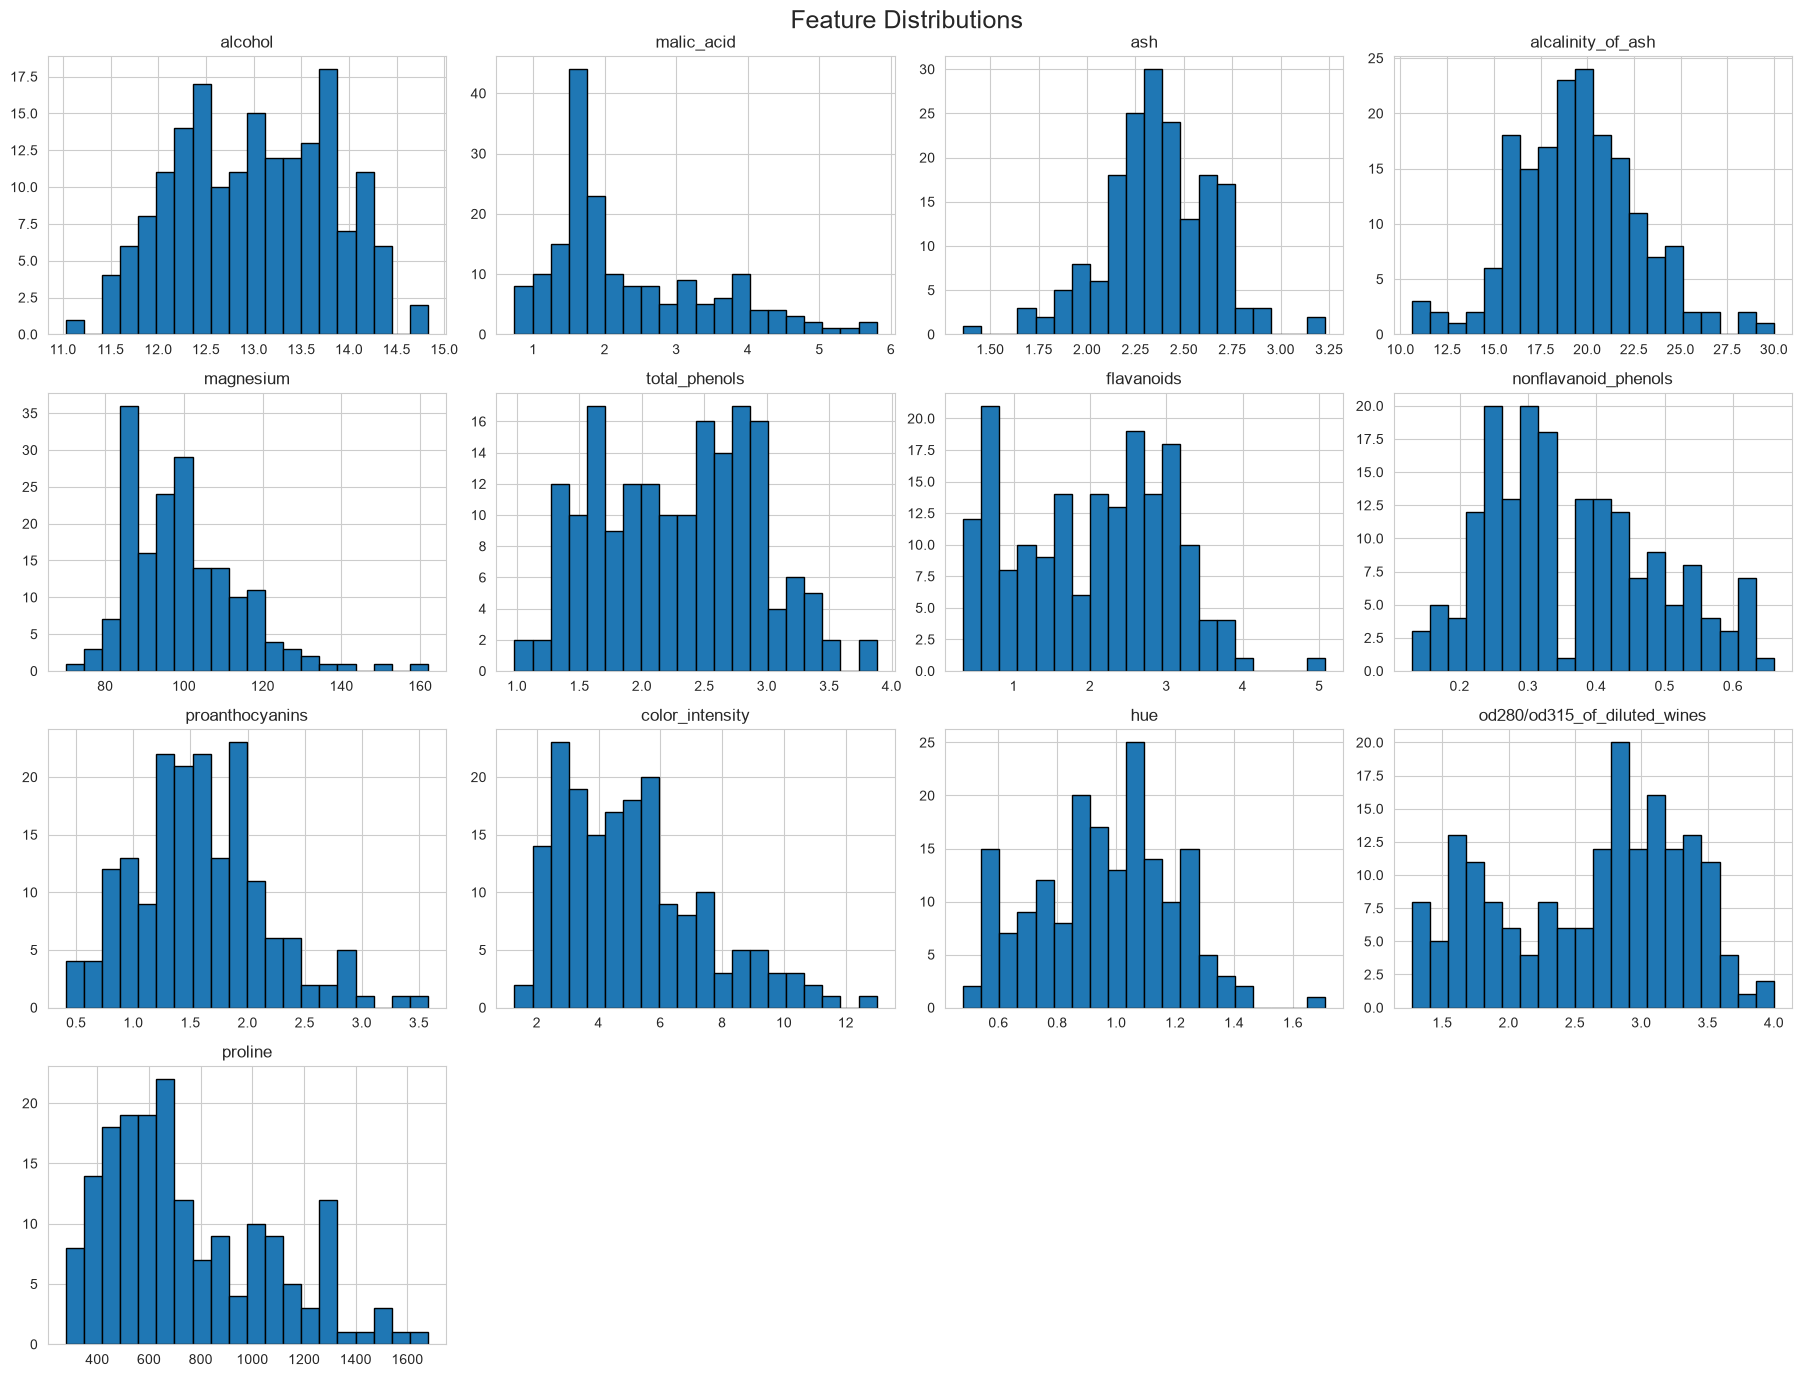

In [4]:
# =========================
# 3. Distribution Plots
# =========================
features = wine.feature_names

df[features].hist(
    figsize=(18, 14),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Feature Distributions", fontsize=18)
plt.tight_layout()
plt.show()



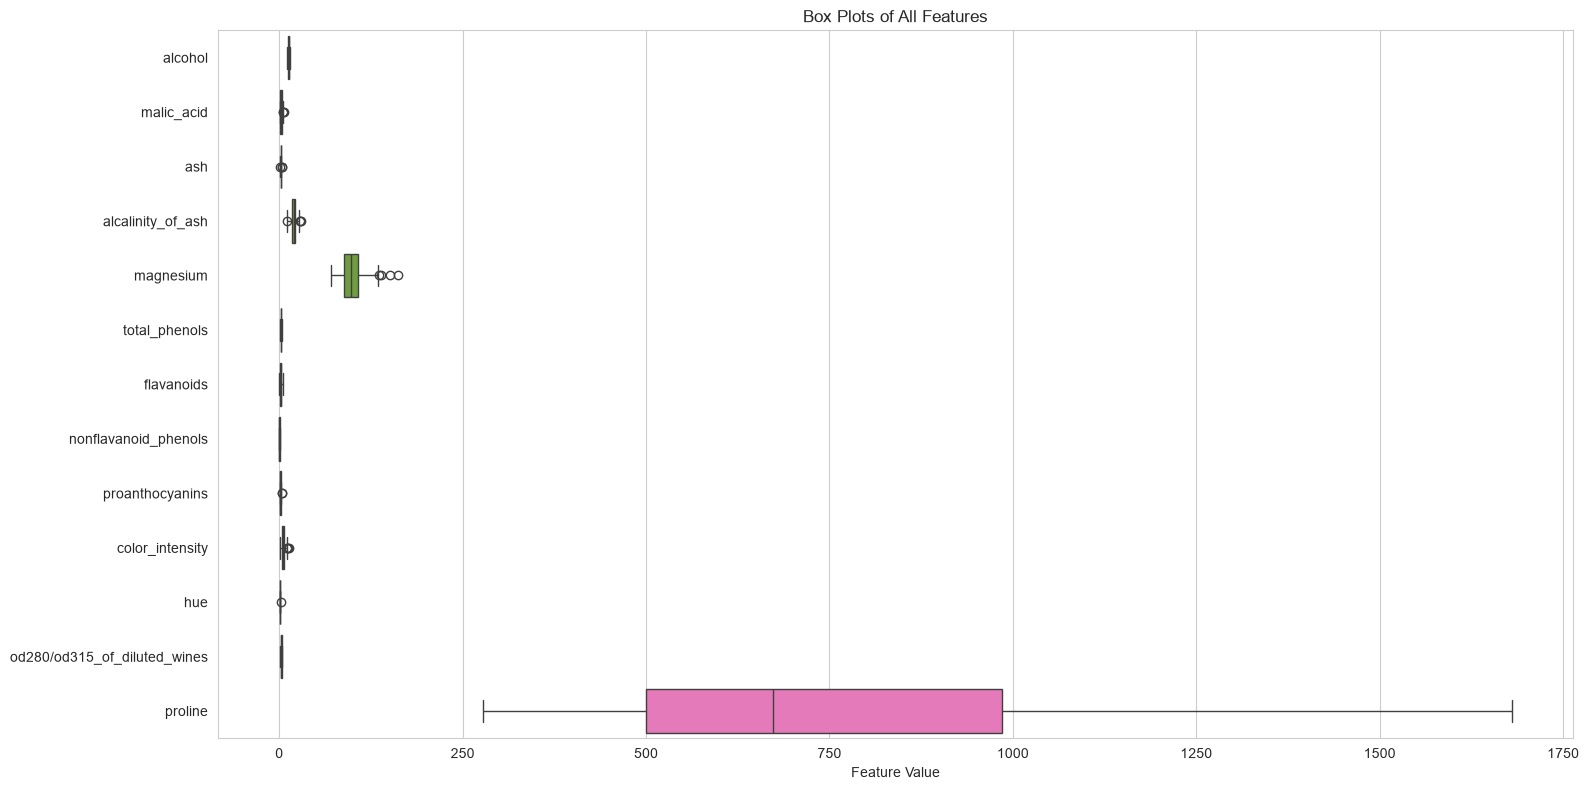

In [5]:
# =========================
# 4. Box Plots
# =========================
plt.figure(figsize=(16, 8))

sns.boxplot(data=df[features], orient="h")

plt.title("Box Plots of All Features")
plt.xlabel("Feature Value")
plt.tight_layout()
plt.show()



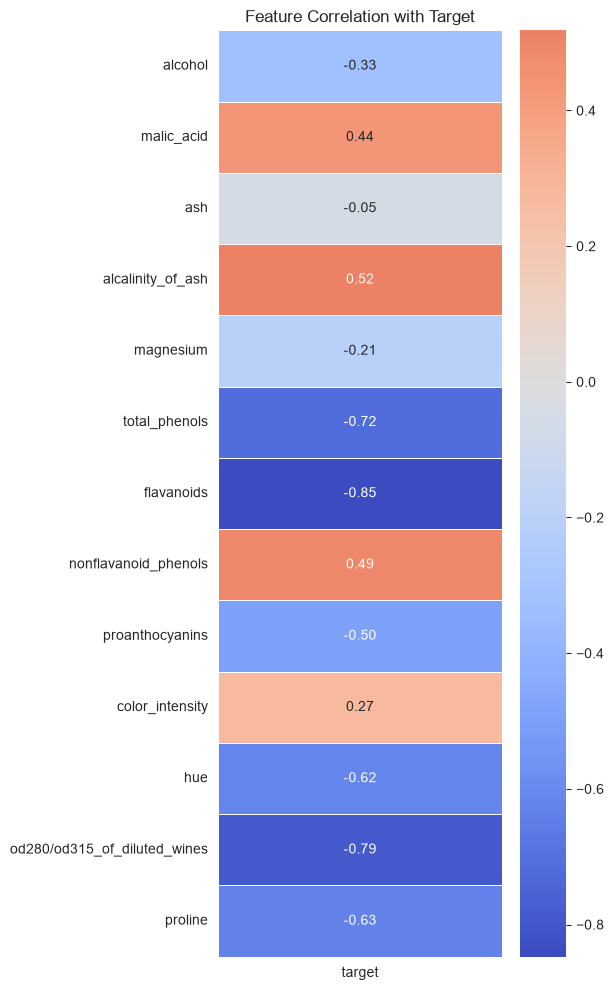

In [8]:

# =========================
# 5. Correlation with Target
# =========================

correlation_matrix = df.corr(numeric_only=True)[["target"]].drop("target")

plt.figure(figsize=(6, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Feature Correlation with Target")
plt.tight_layout()
plt.show()


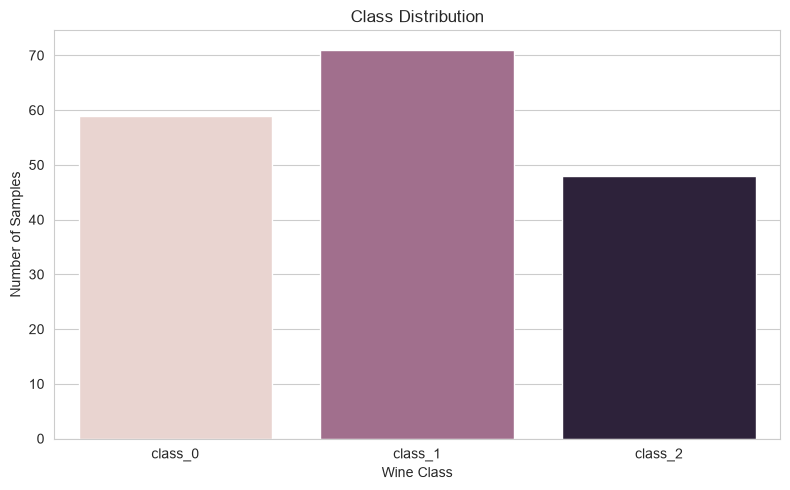


Class Counts:
target
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


In [7]:
# =========================
# 6. Class Distribution
# =========================
class_counts = df["target"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="target", hue="target", legend=False)

plt.title("Class Distribution")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.xticks(
    ticks=[0, 1, 2],
    labels=wine.target_names
)

plt.tight_layout()
plt.show()

print("\nClass Counts:")
print(class_counts.rename(index=dict(enumerate(wine.target_names))))

In [5]:
X = df.drop("target", axis=1)
y = df["target"]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
# =========================
# 1. Build Encoder
# =========================

input_layer = Input(shape=(13,), name="input")

encoder_1 = Dense(64, activation="relu")(input_layer)
encoder_2 = Dense(32, activation="relu")(encoder_1)

latent = Dense(5, activation="relu", name="latent")(encoder_2)

encoder = Model(
    inputs=input_layer,
    outputs=latent,
    name="Encoder"
)


In [9]:
# =========================
# 2. Build Decoder
# =========================

decoder_input = Input(shape=(5,), name="decoder_input")

decoder_1 = Dense(32, activation="relu")(decoder_input)
decoder_2 = Dense(64, activation="relu")(decoder_1)

output_layer = Dense(13, activation="linear")(decoder_2)

decoder = Model(
    inputs=decoder_input,
    outputs=output_layer,
    name="Decoder"
)

In [10]:
# =========================
# 3. Build Autoencoder
# =========================

autoencoder_output = decoder(encoder(input_layer))

autoencoder = Model(
    inputs=input_layer,
    outputs=autoencoder_output,
    name="Autoencoder"
)

In [11]:
# =========================
# 4. Compile Model
# =========================

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()


Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)                   │ (None, 13)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Encoder (Functional)                 │ (None, 5)                   │           3,141 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Decoder (Functional)                 │ (None, 13)                  │           3,149 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,290 (24.57 KB)

 Trainable params: 6,290 (24.57 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# =========================
# 5. Train Encoder-Decoder
# =========================

history = autoencoder.fit(
    X_train_scaled,
    X_train_scaled,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)


Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - loss: 0.9697 - val_loss: 1.0772
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.9449 - val_loss: 1.0640
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.9144 - val_loss: 1.0385
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.8624 - val_loss: 0.9965
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.7957 - val_loss: 0.9391
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.7413 - val_loss: 0.8857
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.6953 - val_loss: 0.8212
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.6452 - val_loss: 0.7426
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.5959 - val_loss: 0.6496
Epoch 10/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.5387 - val_loss: 0.5816
Epoch 11/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.4946 - val_loss: 0.5347
Epoch 12/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.4630 - val_lo

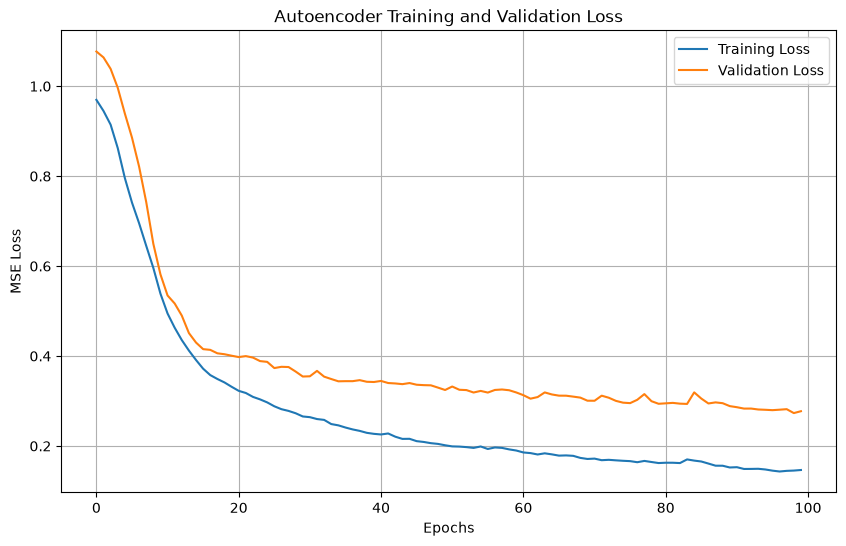

In [13]:
# =========================
# 6. Plot Training & Validation Loss
# =========================

plt.figure(figsize=(10, 6))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)
plt.show()

In [14]:
# =========================
# 7. Extract Latent Features
# =========================

X_train_encoded = encoder.predict(X_train_scaled)
X_test_encoded = encoder.predict(X_test_scaled)

print("Original Training Shape:", X_train_scaled.shape)
print("Encoded Training Shape:", X_train_encoded.shape)

print("Original Testing Shape:", X_test_scaled.shape)
print("Encoded Testing Shape:", X_test_encoded.shape)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
Original Training Shape: (142, 13)
Encoded Training Shape: (142, 5)
Original Testing Shape: (36, 13)
Encoded Testing Shape: (36, 5)


In [17]:
# Model A: Encoded Features Classifier

model_encoded = Sequential([
    Input(shape=(5,)),

    Dense(32, activation="relu"),
    Dense(16, activation="relu"),

    Dense(3, activation="softmax")
])

model_encoded.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_encoded.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                      │ (None, 32)                  │             192 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 3)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 771 (3.01 KB)

 Trainable params: 771 (3.01 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:

# Model B: Original Features Classifier

model_original = Sequential([
    Input(shape=(13,)),

    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),

    Dense(3, activation="softmax")
])

model_original.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_original.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                      │ (None, 64)                  │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 3)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,555 (13.89 KB)

 Trainable params: 3,555 (13.89 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
X_train_enc, X_val_enc, y_train_cls, y_val_cls = train_test_split(
    X_train_encoded,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

X_train_org, X_val_org, _, _ = train_test_split(
    X_train_scaled,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Training settings
epochs = 100
batch_size = 16

# Train Encoded Model
history_encoded = model_encoded.fit(
    X_train_enc,
    y_train_cls,
    validation_data=(X_val_enc, y_val_cls),
    epochs=epochs,
    batch_size=batch_size,
    verbose=1
)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.3982 - loss: 1.3506 - val_accuracy: 0.4828 - val_loss: 1.2319
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4071 - loss: 1.1875 - val_accuracy: 0.4828 - val_loss: 1.0991
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4690 - loss: 1.0473 - val_accuracy: 0.4828 - val_loss: 1.0021
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5133 - loss: 0.9540 - val_accuracy: 0.4483 - val_loss: 0.9150
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6283 - loss: 0.8665 - val_accuracy: 0.7586 - val_loss: 0.8485
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7876 - loss: 0.7952 - val_accuracy: 0.7586 - val_loss: 0.8012
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8761 - loss: 0.7530 - val_accuracy: 0.7586 - val_loss: 0.7627
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9115 - loss: 0.7134 - val_accuracy: 0.7931 - val_loss:

In [20]:
# Train Original Model
history_original = model_original.fit(
    X_train_org,
    y_train_cls,
    validation_data=(X_val_org, y_val_cls),
    epochs=epochs,
    batch_size=batch_size,
    verbose=1
)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.3982 - loss: 1.0566 - val_accuracy: 0.6207 - val_loss: 0.9445
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5841 - loss: 0.9235 - val_accuracy: 0.7241 - val_loss: 0.8325
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8142 - loss: 0.8059 - val_accuracy: 0.8621 - val_loss: 0.7220
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9115 - loss: 0.6866 - val_accuracy: 0.8966 - val_loss: 0.6062
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9646 - loss: 0.5571 - val_accuracy: 0.9310 - val_loss: 0.4948
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9735 - loss: 0.4377 - val_accuracy: 0.9655 - val_loss: 0.3935
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9646 - loss: 0.3401 - val_accuracy: 0.9655 - val_loss: 0.3212
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9735 - loss: 0.2658 - val_accuracy: 0.9655 - val_loss:

In [22]:
# =========================
# Predictions
# =========================

y_pred_encoded = np.argmax(
    model_encoded.predict(X_test_encoded),
    axis=1
)

y_pred_original = np.argmax(
    model_original.predict(X_test_scaled),
    axis=1
)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


In [23]:
# =========================
# Evaluation Function
# =========================

def evaluate_model(y_true, y_pred, model_name):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred, average="macro"
    )

    recall = recall_score(
        y_true, y_pred, average="macro"
    )

    f1 = f1_score(
        y_true, y_pred, average="macro"
    )

    print(f"\n===== {model_name} =====")

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1-Score :", round(f1, 4))

    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            y_pred,
            target_names=wine.target_names
        )
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }


In [24]:
# Evaluate Encoded Model
results_encoded = evaluate_model(
    y_test,
    y_pred_encoded,
    "Encoded Features Model"
)


===== Encoded Features Model =====
Accuracy : 0.9444
Precision: 0.9429
Recall   : 0.9429
F1-Score : 0.9429

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      0.93      0.93        14
     class_2       0.90      0.90      0.90        10

    accuracy                           0.94        36
   macro avg       0.94      0.94      0.94        36
weighted avg       0.94      0.94      0.94        36



In [25]:
# Evaluate Original Model
results_original = evaluate_model(
    y_test,
    y_pred_original,
    "Original Features Model"
)




===== Original Features Model =====
Accuracy : 0.9722
Precision: 0.9778
Recall   : 0.9667
F1-Score : 0.971

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



In [26]:
# =========================
# Comparison Table
# =========================

comparison = pd.DataFrame(
    [results_encoded, results_original],
    index=["Encoded Features", "Original Features"]
)

print("\nModel Comparison:")
print(comparison.round(4))


Model Comparison:
                   Accuracy  Precision  Recall  F1-Score
Encoded Features     0.9444     0.9429  0.9429    0.9429
Original Features    0.9722     0.9778  0.9667    0.9710


Text(145.38563368055554, 0.5, 'Actual')

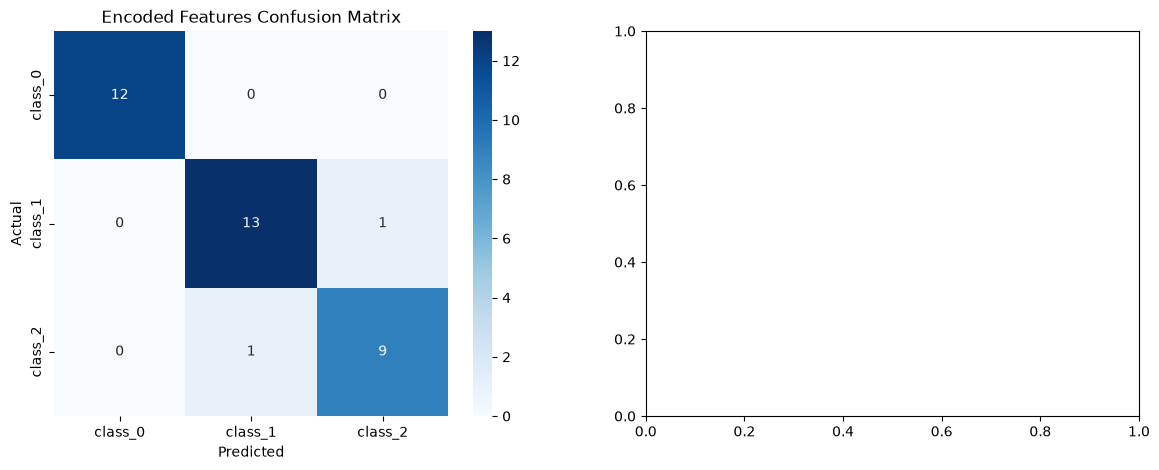

In [27]:
# Calculate Confusion Matrices

cm_encoded = confusion_matrix(y_test, y_pred_encoded)
cm_original = confusion_matrix(y_test, y_pred_original)

# Plot both matrices

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    cm_encoded,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=wine.target_names,
    yticklabels=wine.target_names,
    ax=axes[0]
)



In [29]:
axes[0].set_title("Encoded Features Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
sns.heatmap(
    cm_original,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=wine.target_names,
    yticklabels=wine.target_names,
    ax=axes[1]
)

axes[1].set_title("Original Features Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

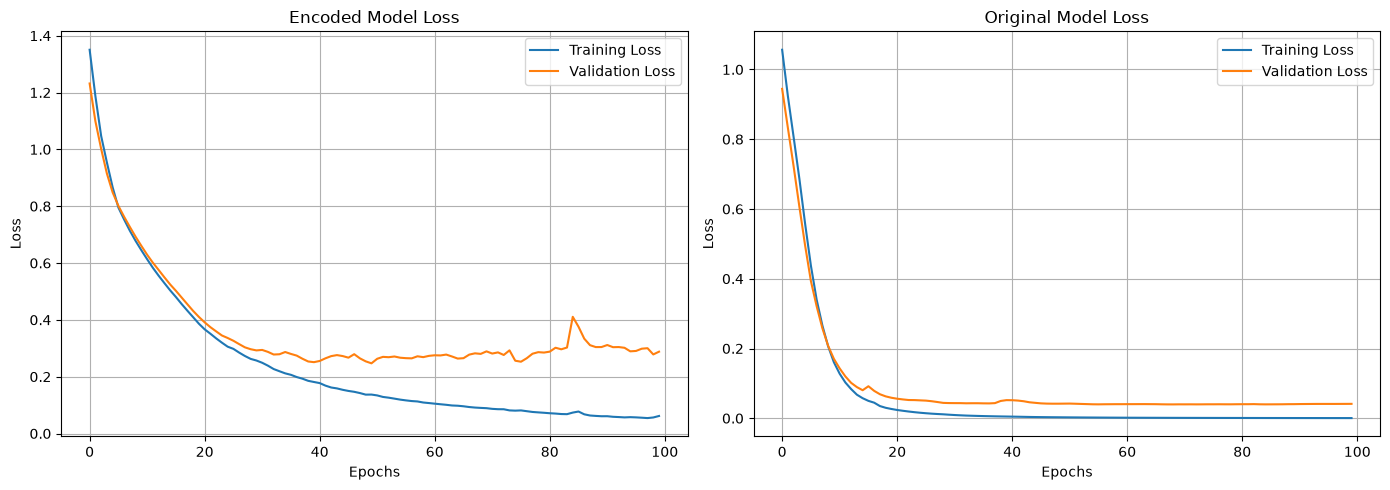

In [30]:

# Plot Classification Loss

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Encoded Model Loss

axes[0].plot(
    history_encoded.history["loss"],
    label="Training Loss"
)

axes[0].plot(
    history_encoded.history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Encoded Model Loss")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)


# Original Model Loss

axes[1].plot(
    history_original.history["loss"],
    label="Training Loss"
)

axes[1].plot(
    history_original.history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("Original Model Loss")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [32]:
# Fit PCA on encoded training features
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_encoded)
X_test_pca = pca.transform(X_test_encoded)

# Combine train and test for visualization
X_all_pca = np.vstack([X_train_pca, X_test_pca])

y_all = np.concatenate([
    np.array(y_train),
    np.array(y_test)
])

split_labels = np.array(
    ["Train"] * len(y_train) +
    ["Test"] * len(y_test)
)

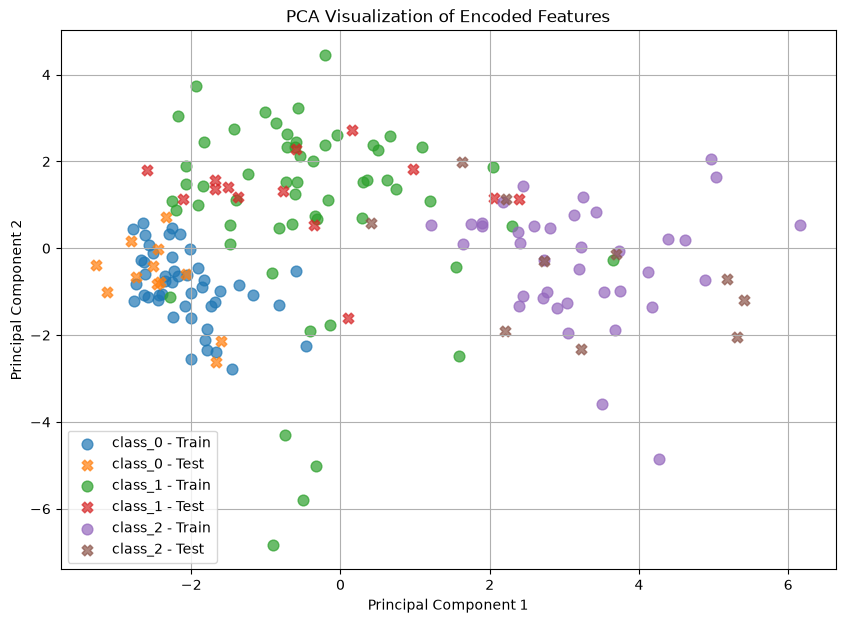

Explained Variance Ratio: [0.41306266 0.2608775 ]
Total Explained Variance: 0.6739402


In [33]:
# Plot PCA
plt.figure(figsize=(10, 7))

for class_id, class_name in enumerate(wine.target_names):

    for split_name, marker in [
        ("Train", "o"),
        ("Test", "X")
    ]:

        mask = (
            (y_all == class_id) &
            (split_labels == split_name)
        )

        plt.scatter(
            X_all_pca[mask, 0],
            X_all_pca[mask, 1],
            label=f"{class_name} - {split_name}",
            marker=marker,
            alpha=0.7,
            s=60
        )

plt.title("PCA Visualization of Encoded Features")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.grid(True)
plt.show()

print(
    "Explained Variance Ratio:",
    pca.explained_variance_ratio_
)

print(
    "Total Explained Variance:",
    pca.explained_variance_ratio_.sum()
)